In [ ]:
!pip -q install -U transformers accelerate faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 61.6 MB/s eta 0:00:00


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

PyTorch: 2.11.0+cpu
CUDA available: False


In [3]:
from pathlib import Path

VEHICLIQ_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ"
)

DATASET_ROOT = (
    VEHICLIQ_ROOT /
    "datasets" /
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL"
)

PROCESSED_ROOT = (
    DATASET_ROOT /
    "processed"
)

METADATA_ROOT = (
    PROCESSED_ROOT /
    "metadata"
)

EMBEDDING_ROOT = (
    PROCESSED_ROOT /
    "embeddings" /
    "siglip2"
)

EMBEDDING_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("VehicleIQ:", VEHICLIQ_ROOT)
print("Dataset:", DATASET_ROOT)
print("Processed:", PROCESSED_ROOT)
print("Metadata:", METADATA_ROOT)
print("Embeddings:", EMBEDDING_ROOT)

VehicleIQ: /content/drive/MyDrive/VehicleIQ
Dataset: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL
Processed: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed
Metadata: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata
Embeddings: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2


In [4]:
required_paths = {
    "processed dataset": PROCESSED_ROOT,
    "train crops": PROCESSED_ROOT / "train",
    "test crops": PROCESSED_ROOT / "test",
    "train metadata": METADATA_ROOT / "train_tracks.json",
    "test metadata": METADATA_ROOT / "test_tracks.json",
    "test queries": METADATA_ROOT / "test_queries.json",
    "sampled metadata": METADATA_ROOT / "train_sampled_8.json",
}

for name, path in required_paths.items():
    print(
        f"{name:20s}:",
        "✓" if path.exists() else "✗",
        path
    )

processed dataset   : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed
train crops         : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train
test crops          : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/test
train metadata      : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/train_tracks.json
test metadata       : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/test_tracks.json
test queries        : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/test_queries.json
sampled metadata    : ✓ /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/train_sampled_8.json


In [5]:
import json

with open(
    METADATA_ROOT / "train_sampled_8.json",
    "r",
    encoding="utf-8"
) as f:
    sampled = json.load(f)

print("Vehicles:", len(sampled))

total_sampled_images = sum(
    len(record["images"])
    for record in sampled.values()
)

print(
    "Representative images:",
    total_sampled_images
)

Vehicles: 2155
Representative images: 17025


In [6]:
vehicle_id = next(iter(sampled))

record = sampled[vehicle_id]

print("Vehicle ID:")
print(vehicle_id)

print("\nNumber of representative images:")
print(len(record["images"]))

print("\nFirst image record:")
print(record["images"][0])

print("\nKeys in image record:")
print(record["images"][0].keys())

Vehicle ID:
b06c903c-a25d-45fe-b0d5-294f72e34023

Number of representative images:
7

First image record:
{'frame_number': 1, 'source_frame': 'validation/S02/c006/img1/000001.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg'}

Keys in image record:
dict_keys(['frame_number', 'source_frame', 'crop_path'])


In [7]:
print("\nRepresentative images:")

for image_info in record["images"]:
    print(image_info)


Representative images:
{'frame_number': 1, 'source_frame': 'validation/S02/c006/img1/000001.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg'}
{'frame_number': 2, 'source_frame': 'validation/S02/c006/img1/000002.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000002.jpg'}
{'frame_number': 3, 'source_frame': 'validation/S02/c006/img1/000003.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000003.jpg'}
{'frame_number': 4, 'source_frame': 'validation/S02/c006/img1/000004.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000004.jpg'}
{'frame_number': 5, 'source_frame': 'validation/S02/c006/img1/000005.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000005.jpg'}
{'frame_number': 6, 'source_frame': 'validation/S02/c006/img1/000006.jpg', 'crop_path': 'train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000006.jpg'}
{'frame_number': 7, 'source_

In [ ]:
from transformers import AutoProcessor, AutoModel

MODEL_ID = "google/siglip2-base-patch16-224"

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID
)

model = AutoModel.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
).to(device)

model.eval()

print("Model:", MODEL_ID)
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Model: google/siglip2-base-patch16-224
Device: cuda


In [8]:
import torch.nn.functional as F

def encode_images(images):

    if not isinstance(images, list):
        images = [images]

    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if torch.is_tensor(value)
    }

    with torch.inference_mode():

        output = model.get_image_features(
            **inputs
        )

    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings

In [9]:
from PIL import Image

first_image_path = (
    PROCESSED_ROOT /
    record["images"][0]["crop_path"]
)

image = Image.open(
    first_image_path
).convert("RGB")

embedding = encode_images(
    [image]
)

print("Embedding shape:", embedding.shape)
print("Embedding dtype:", embedding.dtype)

NameError: name 'processor' is not defined

In [ ]:
test_images = []

for vehicle_id, record in list(sampled.items())[:8]:

    for image_info in record["images"]:

        image_path = (
            PROCESSED_ROOT /
            image_info["crop_path"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        test_images.append(image)

print("Test images:", len(test_images))

Test images: 63


In [ ]:
test_embeddings = encode_images(
    test_images
)

print(
    "Batch embedding shape:",
    test_embeddings.shape
)

Batch embedding shape: torch.Size([63, 768])


In [ ]:
vehicle_ids = list(sampled.keys())

print("Vehicles to encode:", len(vehicle_ids))

print("\nFirst 5 vehicle IDs:")
for vid in vehicle_ids[:5]:
    print(vid)

Vehicles to encode: 2155

First 5 vehicle IDs:
b06c903c-a25d-45fe-b0d5-294f72e34023
3a02a86d-154b-4ee2-bd5e-a0811113a9d8
eb184f7c-35c7-4f3e-af52-1db57fb087d4
abd32535-8acb-49c5-8da4-9e904d263d8c
3819f85b-103a-4f0b-b0f1-49e6b2fedb68


In [ ]:
VEHICLE_BATCH_SIZE = 8

vehicle_ids = list(sampled.keys())

vehicle_batches = [
    vehicle_ids[i:i + VEHICLE_BATCH_SIZE]
    for i in range(
        0,
        len(vehicle_ids),
        VEHICLE_BATCH_SIZE
    )
]

print("Total vehicles:", len(vehicle_ids))
print("Vehicle batches:", len(vehicle_batches))
print("Vehicles per batch:", VEHICLE_BATCH_SIZE)

Total vehicles: 2155
Vehicle batches: 270
Vehicles per batch: 8


In [ ]:
from PIL import Image

def load_vehicle_images(vehicle_id):

    record = sampled[vehicle_id]

    images = []
    image_paths = []

    for image_info in record["images"]:

        image_path = (
            PROCESSED_ROOT /
            image_info["crop_path"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        images.append(image)
        image_paths.append(image_path)

    return images, image_paths

In [ ]:
test_vehicle_id = vehicle_ids[0]

test_images, test_paths = load_vehicle_images(
    test_vehicle_id
)

print("Vehicle:", test_vehicle_id)
print("Images:", len(test_images))

for path in test_paths:
    print(path)

Vehicle: b06c903c-a25d-45fe-b0d5-294f72e34023
Images: 7
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000002.jpg
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000003.jpg
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000004.jpg
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000005.jpg
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000006.jpg
/content/drive/MyDrive/VehicleIQ

In [ ]:
import time
import numpy as np

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.time()

test_frame_embeddings = encode_images(
    test_images
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.time() - start_time

print("Frame embeddings:")
print(test_frame_embeddings.shape)

print(
    f"Encoding time: {elapsed:.2f} seconds"
)

Frame embeddings:
torch.Size([7, 768])
Encoding time: 0.06 seconds


In [ ]:
test_frame_embeddings = (
    test_frame_embeddings
    .float()
)

test_vehicle_embedding = (
    test_frame_embeddings
    .mean(dim=0)
)

test_vehicle_embedding = F.normalize(
    test_vehicle_embedding,
    p=2,
    dim=0
)

print(
    "Vehicle embedding shape:",
    test_vehicle_embedding.shape
)

print(
    "Embedding norm:",
    test_vehicle_embedding.norm().item()
)

Vehicle embedding shape: torch.Size([768])
Embedding norm: 1.0


In [ ]:
BENCHMARK_VEHICLES = vehicle_ids[:8]

benchmark_images = []
benchmark_mapping = []

for vehicle_id in BENCHMARK_VEHICLES:

    images, _ = load_vehicle_images(
        vehicle_id
    )

    benchmark_images.extend(images)

    benchmark_mapping.extend(
        [vehicle_id] * len(images)
    )

print(
    "Benchmark vehicles:",
    len(BENCHMARK_VEHICLES)
)

print(
    "Benchmark images:",
    len(benchmark_images)
)

Benchmark vehicles: 8
Benchmark images: 63


In [ ]:
if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.time()

benchmark_frame_embeddings = encode_images(
    benchmark_images
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.time() - start_time

print(
    "Frame embeddings:",
    benchmark_frame_embeddings.shape
)

print(
    f"Encoding time: {elapsed:.2f} seconds"
)

print(
    f"Images/sec: "
    f"{len(benchmark_images) / elapsed:.2f}"
)

Frame embeddings: torch.Size([63, 768])
Encoding time: 0.35 seconds
Images/sec: 181.92


In [ ]:
CHECKPOINT_ROOT = (
    EMBEDDING_ROOT /
    "checkpoints"
)

CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Checkpoint directory:",
    CHECKPOINT_ROOT
)

Checkpoint directory: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2/checkpoints


In [ ]:
# import time
# import numpy as np
# import torch
# from tqdm.auto import tqdm

# vehicle_embeddings = []
# processed_vehicle_ids = []

# CHECKPOINT_EVERY = 50

# start_time = time.time()

# for batch_index, batch_vehicle_ids in enumerate(
#     tqdm(
#         vehicle_batches,
#         desc="Encoding vehicles"
#     )
# ):

#     batch_images = []
#     batch_mapping = []

#     # --------------------------------------------------
#     # Load sampled crops for this vehicle batch
#     # --------------------------------------------------

#     for vehicle_id in batch_vehicle_ids:

#         images, _ = load_vehicle_images(
#             vehicle_id
#         )

#         batch_images.extend(images)

#         batch_mapping.extend(
#             [vehicle_id] * len(images)
#         )

#     if not batch_images:
#         continue

#     # --------------------------------------------------
#     # SigLIP encoding
#     # --------------------------------------------------

#     frame_embeddings = encode_images(
#         batch_images
#     )

#     frame_embeddings = (
#         frame_embeddings
#         .float()
#         .cpu()
#     )

#     # --------------------------------------------------
#     # Convert frame embeddings → vehicle embeddings
#     # --------------------------------------------------

#     start_index = 0

#     for vehicle_id in batch_vehicle_ids:

#         number_of_frames = batch_mapping.count(
#             vehicle_id
#         )

#         vehicle_frames = frame_embeddings[
#             start_index:
#             start_index + number_of_frames
#         ]

#         start_index += number_of_frames

#         if len(vehicle_frames) == 0:
#             continue

#         vehicle_embedding = (
#             vehicle_frames.mean(dim=0)
#         )

#         vehicle_embedding = F.normalize(
#             vehicle_embedding,
#             p=2,
#             dim=0
#         )

#         vehicle_embeddings.append(
#             vehicle_embedding.numpy()
#         )

#         processed_vehicle_ids.append(
#             vehicle_id
#         )

#     # --------------------------------------------------
#     # Checkpoint
#     # --------------------------------------------------

#     if (
#         (batch_index + 1) % CHECKPOINT_EVERY == 0
#         or
#         batch_index == len(vehicle_batches) - 1
#     ):

#         partial_embeddings = np.asarray(
#             vehicle_embeddings,
#             dtype=np.float32
#         )

#         np.save(
#             CHECKPOINT_ROOT /
#             f"embeddings_{len(processed_vehicle_ids)}.npy",
#             partial_embeddings
#         )

#         with open(
#             CHECKPOINT_ROOT /
#             f"vehicle_ids_{len(processed_vehicle_ids)}.json",
#             "w"
#         ) as f:

#             json.dump(
#                 processed_vehicle_ids,
#                 f
#             )

#         print(
#             f"\nCheckpoint saved: "
#             f"{len(processed_vehicle_ids)} vehicles"
#         )

# elapsed = time.time() - start_time

# vehicle_embeddings = np.asarray(
#     vehicle_embeddings,
#     dtype=np.float32
# )

# print("\n====================================")
# print("VEHICLE EMBEDDING EXTRACTION COMPLETE")
# print("====================================")
# print(
#     "Vehicles:",
#     len(processed_vehicle_ids)
# )
# print(
#     "Embedding matrix:",
#     vehicle_embeddings.shape
# )
# print(
#     f"Runtime: {elapsed / 60:.2f} minutes"
# )

In [ ]:
import re
import numpy as np

checkpoint_files = list(
    CHECKPOINT_ROOT.glob(
        "embeddings_*.npy"
    )
)

def get_checkpoint_number(path):
    match = re.search(
        r"embeddings_(\d+)\.npy",
        path.name
    )

    if match:
        return int(match.group(1))

    return -1


latest_checkpoint = max(
    checkpoint_files,
    key=get_checkpoint_number
)

completed_count = get_checkpoint_number(
    latest_checkpoint
)

ids_file = (
    CHECKPOINT_ROOT /
    f"vehicle_ids_{completed_count}.json"
)

completed_embeddings = np.load(
    latest_checkpoint
)

with open(ids_file, "r") as f:
    completed_vehicle_ids = json.load(f)

print("Latest checkpoint:")
print(latest_checkpoint)

print(
    "Completed vehicles:",
    completed_count
)

print(
    "Embedding shape:",
    completed_embeddings.shape
)

print(
    "Vehicle IDs:",
    len(completed_vehicle_ids)
)

Latest checkpoint:
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2/checkpoints/embeddings_2000.npy
Completed vehicles: 2000
Embedding shape: (2000, 768)
Vehicle IDs: 2000


In [ ]:
completed_set = set(
    completed_vehicle_ids
)

remaining_vehicle_ids = [
    vehicle_id
    for vehicle_id in vehicle_ids
    if vehicle_id not in completed_set
]

print(
    "Total vehicles:",
    len(vehicle_ids)
)

print(
    "Already completed:",
    len(completed_vehicle_ids)
)

print(
    "Remaining:",
    len(remaining_vehicle_ids)
)

Total vehicles: 2155
Already completed: 2000
Remaining: 155


In [ ]:
def encode_images(images):

    if not isinstance(images, list):
        images = [images]

    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if torch.is_tensor(value)
    }

    with torch.inference_mode():

        output = model.get_image_features(
            **inputs
        )

    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings

In [ ]:
from PIL import Image

def load_vehicle_images(vehicle_id):

    record = sampled[vehicle_id]

    images = []

    for image_info in record["images"]:

        image_path = (
            PROCESSED_ROOT /
            image_info["crop_path"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        images.append(image)

    return images

In [ ]:
test_vehicle_id = remaining_vehicle_ids[0]

test_images = load_vehicle_images(
    test_vehicle_id
)

print(
    "Vehicle:",
    test_vehicle_id
)

print(
    "Sampled images:",
    len(test_images)
)

test_embedding = encode_images(
    test_images
)

print(
    "Frame embedding shape:",
    test_embedding.shape
)

Vehicle: efa1b2de-4699-46f8-bdfb-2a60fa02568a
Sampled images: 8
Frame embedding shape: torch.Size([8, 768])


In [ ]:
test_vehicle_embedding = (
    test_embedding
    .float()
    .mean(dim=0)
)

test_vehicle_embedding = F.normalize(
    test_vehicle_embedding,
    p=2,
    dim=0
)

print(
    "Vehicle embedding shape:",
    test_vehicle_embedding.shape
)

print(
    "Norm:",
    test_vehicle_embedding.norm().item()
)

Vehicle embedding shape: torch.Size([768])
Norm: 1.0


In [ ]:
# from tqdm.auto import tqdm

# remaining_embeddings = []
# new_vehicle_ids = []

# start_time = time.time()

# for vehicle_id in tqdm(
#     remaining_vehicle_ids,
#     desc="Encoding remaining vehicles"
# ):

#     images = load_vehicle_images(
#         vehicle_id
#     )

#     if not images:
#         continue

#     frame_embeddings = encode_images(
#         images
#     )

#     frame_embeddings = (
#         frame_embeddings
#         .float()
#     )

#     # Mean pooling across representative frames
#     vehicle_embedding = (
#         frame_embeddings
#         .mean(dim=0)
#     )

#     # Normalize the final vehicle vector
#     vehicle_embedding = F.normalize(
#         vehicle_embedding,
#         p=2,
#         dim=0
#     )

#     remaining_embeddings.append(
#         vehicle_embedding
#         .cpu()
#         .numpy()
#     )

#     new_vehicle_ids.append(
#         vehicle_id
#     )

# elapsed = time.time() - start_time

# print(
#     "\nRemaining vehicles encoded:",
#     len(new_vehicle_ids)
# )

# print(
#     "Remaining embedding matrix:",
#     np.asarray(
#         remaining_embeddings
#     ).shape
# )

# print(
#     f"Runtime: {elapsed / 60:.2f} minutes"
# )

Encoding remaining vehicles:   0%|          | 0/155 [00:00<?, ?it/s]


Remaining vehicles encoded: 155
Remaining embedding matrix: (155, 768)
Runtime: 6.63 minutes


In [ ]:
remaining_embeddings = np.asarray(
    remaining_embeddings,
    dtype=np.float32
)

final_embeddings = np.concatenate(
    [
        completed_embeddings,
        remaining_embeddings
    ],
    axis=0
)

final_vehicle_ids = (
    completed_vehicle_ids
    + new_vehicle_ids
)

print(
    "Final embedding shape:",
    final_embeddings.shape
)

print(
    "Final vehicle count:",
    len(final_vehicle_ids)
)

Final embedding shape: (2155, 768)
Final vehicle count: 2155


In [ ]:
assert final_embeddings.shape == (
    2155,
    768
)

assert len(final_vehicle_ids) == 2155

assert len(
    set(final_vehicle_ids)
) == 2155

norms = np.linalg.norm(
    final_embeddings,
    axis=1
)

assert np.allclose(
    norms,
    1.0,
    atol=1e-3
)

print("================================")
print("FINAL EMBEDDING VALIDATION PASSED")
print("================================")
print("Vehicles :", len(final_vehicle_ids))
print("Dimension:", final_embeddings.shape[1])
print("Shape    :", final_embeddings.shape)
print("Unique IDs:", len(set(final_vehicle_ids)))
print("All normalized: ✓")

FINAL EMBEDDING VALIDATION PASSED
Vehicles : 2155
Dimension: 768
Shape    : (2155, 768)
Unique IDs: 2155
All normalized: ✓


In [ ]:
FINAL_EMBEDDINGS = (
    EMBEDDING_ROOT /
    "vehicle_embeddings.npy"
)

FINAL_IDS = (
    EMBEDDING_ROOT /
    "vehicle_ids.json"
)

np.save(
    FINAL_EMBEDDINGS,
    final_embeddings
)

with open(
    FINAL_IDS,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_vehicle_ids,
        f,
        indent=2
    )

print("================================")
print("FINAL VEHICLE GALLERY SAVED")
print("================================")

print(
    "Embeddings:",
    FINAL_EMBEDDINGS
)

print(
    "Vehicle IDs:",
    FINAL_IDS
)

FINAL VEHICLE GALLERY SAVED
Embeddings: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2/vehicle_embeddings.npy
Vehicle IDs: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2/vehicle_ids.json


In [10]:
!pip -q install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 49.4 MB/s eta 0:00:00


In [11]:
import faiss
import numpy as np
import json
from pathlib import Path

print("FAISS version:", faiss.__version__)

FAISS version: 1.15.0


In [12]:
EMBEDDING_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ/"
    "datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/"
    "processed/embeddings/siglip2"
)

embeddings = np.load(
    EMBEDDING_ROOT / "vehicle_embeddings.npy"
)

with open(
    EMBEDDING_ROOT / "vehicle_ids.json",
    "r",
    encoding="utf-8"
) as f:
    vehicle_ids = json.load(f)

print("Embeddings:", embeddings.shape)
print("Vehicle IDs:", len(vehicle_ids))
print("dtype:", embeddings.dtype)

Embeddings: (2155, 768)
Vehicle IDs: 2155
dtype: float32


In [13]:
dimension = embeddings.shape[1]

index = faiss.IndexFlatIP(
    dimension
)

index.add(
    embeddings
)

print("FAISS dimension:", index.d)
print("Vectors stored:", index.ntotal)

FAISS dimension: 768
Vectors stored: 2155


In [14]:
FAISS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_gallery.faiss"
)

faiss.write_index(
    index,
    str(FAISS_PATH)
)

print(
    "FAISS index saved:"
)

print(FAISS_PATH)

FAISS index saved:
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2/vehicle_gallery.faiss


In [15]:
query_vehicle_index = 0

query_vector = embeddings[
    query_vehicle_index
].reshape(1, -1)

scores, indices = index.search(
    query_vector,
    10
)

print("Query vehicle:")
print(vehicle_ids[query_vehicle_index])

print("\nTop 10 visually similar vehicles:")

for rank, (score, idx) in enumerate(
    zip(scores[0], indices[0]),
    start=1
):
    print(
        f"{rank:2d}. "
        f"{vehicle_ids[idx]} "
        f"similarity={score:.4f}"
    )

Query vehicle:
b06c903c-a25d-45fe-b0d5-294f72e34023

Top 10 visually similar vehicles:
 1. b06c903c-a25d-45fe-b0d5-294f72e34023 similarity=1.0000
 2. 3a02a86d-154b-4ee2-bd5e-a0811113a9d8 similarity=0.9221
 3. 78188194-cb69-450b-853c-1f908fbe793d similarity=0.8813
 4. 49f04a86-ff71-4ad9-bd2d-bc836e3bb446 similarity=0.8714
 5. daaac25a-2e2a-4aff-b617-014a6337e303 similarity=0.8692
 6. aa624084-d66a-42a2-bab4-f8a32846d62c similarity=0.8652
 7. 1dc7c242-b8e8-45ae-bcfc-f3827792cf55 similarity=0.8613
 8. 9ed49959-6448-4807-9c81-85d73f61b70a similarity=0.8594
 9. 959160ff-95bc-4782-9aa9-ecc3f0d1a0cf similarity=0.8572
10. eb184f7c-35c7-4f3e-af52-1db57fb087d4 similarity=0.8550


In [16]:
from pathlib import Path
import numpy as np
import json
import faiss

EMBEDDING_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ/"
    "datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/"
    "processed/embeddings/siglip2"
)

FAISS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_gallery.faiss"
)

EMBEDDINGS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_embeddings.npy"
)

IDS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_ids.json"
)

print("FAISS exists:", FAISS_PATH.exists())
print("Embeddings exists:", EMBEDDINGS_PATH.exists())
print("IDs exists:", IDS_PATH.exists())

FAISS exists: True
Embeddings exists: True
IDs exists: True


In [17]:
index = faiss.read_index(
    str(FAISS_PATH)
)

embeddings = np.load(
    EMBEDDINGS_PATH
)

with open(
    IDS_PATH,
    "r",
    encoding="utf-8"
) as f:
    vehicle_ids = json.load(f)

print("FAISS vectors:", index.ntotal)
print("Embedding shape:", embeddings.shape)
print("Vehicle IDs:", len(vehicle_ids))

FAISS vectors: 2155
Embedding shape: (2155, 768)
Vehicle IDs: 2155


In [18]:
import torch
import torch.nn.functional as F

MODEL_ID = "google/siglip2-base-patch16-224"

if "model" not in globals() or "processor" not in globals():

    from transformers import (
        AutoProcessor,
        AutoModel
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID
    )

    model = AutoModel.from_pretrained(
        MODEL_ID,
        torch_dtype=(
            torch.float16
            if device.type == "cuda"
            else torch.float32
        )
    ).to(device)

    model.eval()

else:

    device = next(
        model.parameters()
    ).device

print("Model:", MODEL_ID)
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Model: google/siglip2-base-patch16-224
Device: cpu


In [19]:
def encode_text(texts):

    if isinstance(texts, str):
        texts = [texts]

    inputs = processor(
        text=texts,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if torch.is_tensor(value)
    }

    with torch.inference_mode():

        output = model.get_text_features(
            **inputs
        )

    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings

In [20]:
query = "a red sedan"

text_embedding = encode_text(
    query
)

print(
    "Query:",
    query
)

print(
    "Embedding shape:",
    text_embedding.shape
)

print(
    "Embedding norm:",
    text_embedding.norm().item()
)

Query: a red sedan
Embedding shape: torch.Size([1, 768])
Embedding norm: 1.0


In [21]:
query_vector = (
    text_embedding
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)

scores, indices = index.search(
    query_vector,
    10
)

print("Query:", query)
print("\nTop 10 results:\n")

for rank, (score, idx) in enumerate(
    zip(scores[0], indices[0]),
    start=1
):

    print(
        f"{rank:2d}. "
        f"{vehicle_ids[idx]} "
        f"similarity={score:.4f}"
    )

Query: a red sedan

Top 10 results:

 1. b1f099fd-e45e-4ded-b183-725741959fba similarity=0.1605
 2. 84345111-4877-4dcf-9331-5ef50aa80fdc similarity=0.1577
 3. 610b30a1-5f40-41d0-9c05-fbd1448d3f6e similarity=0.1575
 4. f70f8c5d-bdab-41f5-8f04-a4b7915d1a06 similarity=0.1575
 5. b994a201-f6da-4e9c-b5cd-85f667aa816b similarity=0.1574
 6. 735d617a-12c6-4144-9b90-dc248076c9dc similarity=0.1556
 7. 870e5570-4c79-42ba-bd97-a862d86004f0 similarity=0.1553
 8. 3a02a86d-154b-4ee2-bd5e-a0811113a9d8 similarity=0.1552
 9. 0ee59af3-1502-494b-a3a3-1c4fade7873b similarity=0.1540
10. cfad5a2f-3aba-450a-8c80-3d76d1dadf62 similarity=0.1538


In [22]:
def semantic_search(
    query,
    top_k=10
):

    # -------------------------------
    # Text → embedding
    # -------------------------------

    text_embedding = encode_text(
        query
    )

    query_vector = (
        text_embedding
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    # -------------------------------
    # FAISS retrieval
    # -------------------------------

    scores, indices = index.search(
        query_vector,
        top_k
    )

    results = []

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):

        results.append(
            {
                "rank": rank,
                "vehicle_id": vehicle_ids[idx],
                "similarity": float(score),
                "faiss_index": int(idx)
            }
        )

    return results

In [23]:
queries = [
    "a red sedan",
    "a white pickup truck",
    "a blue bus",
    "a black car",
    "a motorcycle",
    "a vehicle driving straight",
]

for query in queries:

    results = semantic_search(
        query,
        top_k=5
    )

    print("\n" + "=" * 70)
    print("QUERY:", query)
    print("=" * 70)

    for result in results:

        print(
            f"{result['rank']:2d}. "
            f"{result['vehicle_id']} "
            f"score={result['similarity']:.4f}"
        )


QUERY: a red sedan
 1. b1f099fd-e45e-4ded-b183-725741959fba score=0.1605
 2. 84345111-4877-4dcf-9331-5ef50aa80fdc score=0.1577
 3. 610b30a1-5f40-41d0-9c05-fbd1448d3f6e score=0.1575
 4. f70f8c5d-bdab-41f5-8f04-a4b7915d1a06 score=0.1575
 5. b994a201-f6da-4e9c-b5cd-85f667aa816b score=0.1574

QUERY: a white pickup truck
 1. d1e6f0f2-119c-4aff-9ee9-395d9ff7b458 score=0.1649
 2. 81bfbdeb-9507-4ec0-83cc-d5053400e943 score=0.1632
 3. 8f84c429-2ca5-4c80-bf34-abaa1f3f7b80 score=0.1624
 4. 40a2bb12-ec55-4c34-bdca-78d286eba627 score=0.1617
 5. 7db8f09a-324f-429c-8ed8-40496dd92930 score=0.1612

QUERY: a blue bus
 1. 88121c67-b69a-43c0-bf1c-34f76fb1f827 score=0.1242
 2. 93fdc2b3-71eb-40eb-bc40-e7efc7adb110 score=0.1231
 3. f0cc74b8-e0ab-4ba3-9578-be5ab51d37f3 score=0.1191
 4. efdaed38-f8de-4bc5-bfaf-e38a2fc2b5a8 score=0.1188
 5. eab5c04d-0edc-4aa9-8214-7dd668885ff3 score=0.1183

QUERY: a black car
 1. 4d802d4d-6b22-41c1-9961-5ded239b6a59 score=0.1440
 2. 05d4a2c6-4b04-4535-9c13-fda88a29f2c8 score=0

In [24]:
METADATA_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ/"
    "datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/"
    "processed/metadata"
)

with open(
    METADATA_ROOT / "train_sampled_8.json",
    "r",
    encoding="utf-8"
) as f:

    sampled = json.load(f)

print(
    "Sampled vehicles:",
    len(sampled)
)

Sampled vehicles: 2155


In [25]:
def get_vehicle_image_path(
    vehicle_id
):

    record = sampled.get(
        vehicle_id
    )

    if record is None:
        return None

    images = record.get(
        "images",
        []
    )

    if not images:
        return None

    crop_path = images[0][
        "crop_path"
    ]

    return (
        PROCESSED_ROOT /
        crop_path
    )

In [26]:
def enrich_results(
    results
):

    enriched = []

    for result in results:

        vehicle_id = result[
            "vehicle_id"
        ]

        image_path = (
            get_vehicle_image_path(
                vehicle_id
            )
        )

        enriched_result = {
            **result,
            "image_path": (
                str(image_path)
                if image_path
                else None
            )
        }

        enriched.append(
            enriched_result
        )

    return enriched

In [27]:
query = "a red sedan"

results = semantic_search(
    query,
    top_k=10
)

results = enrich_results(
    results
)

for result in results:

    print(
        f"{result['rank']:2d}. "
        f"{result['vehicle_id']}"
    )

    print(
        f"    similarity: "
        f"{result['similarity']:.4f}"
    )

    print(
        f"    image: "
        f"{result['image_path']}"
    )

    print()

 1. b1f099fd-e45e-4ded-b183-725741959fba
    similarity: 0.1605
    image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b1f099fd-e45e-4ded-b183-725741959fba/frame_001619.jpg

 2. 84345111-4877-4dcf-9331-5ef50aa80fdc
    similarity: 0.1577
    image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/84345111-4877-4dcf-9331-5ef50aa80fdc/frame_000143.jpg

 3. 610b30a1-5f40-41d0-9c05-fbd1448d3f6e
    similarity: 0.1575
    image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/610b30a1-5f40-41d0-9c05-fbd1448d3f6e/frame_001155.jpg

 4. f70f8c5d-bdab-41f5-8f04-a4b7915d1a06
    similarity: 0.1575
    image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/f70f8c5d-bdab-41f5-8f04-a4b7915d1a06/frame_000673.jpg

 5. b994a201-f6da-4e9c-b5cd-85f667aa816b
    similarity: 0.1574
    image: /content/driv

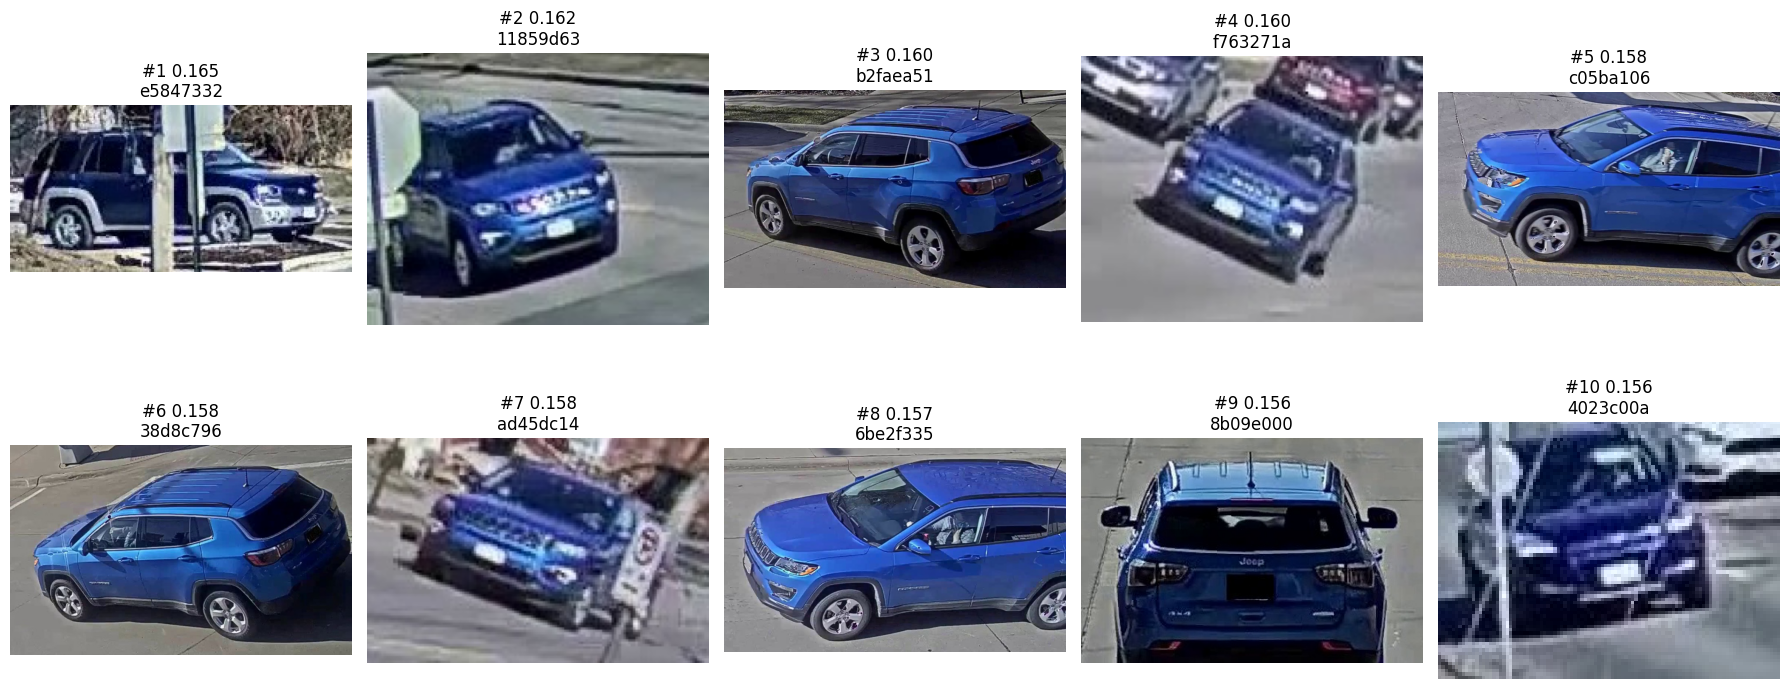

In [28]:
import matplotlib.pyplot as plt

query = "a blue suv"

results = enrich_results(
    semantic_search(
        query,
        top_k=10
    )
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8)
)

for ax, result in zip(
    axes.flatten(),
    results
):

    image_path = result[
        "image_path"
    ]

    image = Image.open(
        image_path
    ).convert("RGB")

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f"#{result['rank']} "
        f"{result['similarity']:.3f}\n"
        f"{result['vehicle_id'][:8]}"
    )

plt.tight_layout()
plt.show()

In [29]:
def similarity_label(
    score
):

    if score >= 0.90:
        return "Very high"

    elif score >= 0.80:
        return "High"

    elif score >= 0.70:
        return "Moderate"

    elif score >= 0.60:
        return "Low"

    else:
        return "Very low"

In [30]:
for result in results:

    result["relevance"] = (
        similarity_label(
            result["similarity"]
        )
    )

    print(
        result["rank"],
        result["similarity"],
        result["relevance"]
    )

1 0.1651267111301422 Very low
2 0.16208995878696442 Very low
3 0.16023385524749756 Very low
4 0.15981441736221313 Very low
5 0.1582331657409668 Very low
6 0.1578327864408493 Very low
7 0.1575545370578766 Very low
8 0.15704068541526794 Very low
9 0.1557208001613617 Very low
10 0.1556512415409088 Very low


In [31]:
test_queries = [
    "a red sedan",
    "a white pickup truck",
    "a blue vehicle",
    "a dark colored car",
    "a large truck",
    "a vehicle moving straight",
]

for query in test_queries:

    results = semantic_search(
        query,
        top_k=5
    )

    print("\n" + "=" * 60)
    print("QUERY:", query)
    print("=" * 60)

    for result in results:

        print(
            f"{result['rank']:2d}. "
            f"{result['similarity']:.4f} "
            f"{result['vehicle_id']}"
        )


QUERY: a red sedan
 1. 0.1605 b1f099fd-e45e-4ded-b183-725741959fba
 2. 0.1577 84345111-4877-4dcf-9331-5ef50aa80fdc
 3. 0.1575 610b30a1-5f40-41d0-9c05-fbd1448d3f6e
 4. 0.1575 f70f8c5d-bdab-41f5-8f04-a4b7915d1a06
 5. 0.1574 b994a201-f6da-4e9c-b5cd-85f667aa816b

QUERY: a white pickup truck
 1. 0.1649 d1e6f0f2-119c-4aff-9ee9-395d9ff7b458
 2. 0.1632 81bfbdeb-9507-4ec0-83cc-d5053400e943
 3. 0.1624 8f84c429-2ca5-4c80-bf34-abaa1f3f7b80
 4. 0.1617 40a2bb12-ec55-4c34-bdca-78d286eba627
 5. 0.1612 7db8f09a-324f-429c-8ed8-40496dd92930

QUERY: a blue vehicle
 1. 0.1475 d1d50d91-7fbe-4b2f-9329-4bc4fd3bea52
 2. 0.1465 11859d63-b9e3-48bd-809c-22c08cdc8c2f
 3. 0.1449 bea8d80d-731e-423d-8a8f-239a4effa801
 4. 0.1441 f763271a-b830-47dd-bd55-196bdb10f6ee
 5. 0.1436 56b69322-75cd-473a-b596-785a4262559b

QUERY: a dark colored car
 1. 0.1469 4d802d4d-6b22-41c1-9961-5ded239b6a59
 2. 0.1436 f91b3130-755b-4a8e-b915-c1350f33c61d
 3. 0.1423 d81fc5f4-2e30-4d41-92b0-b7e635994752
 4. 0.1423 05d4a2c6-4b04-4535-9c13-fd

In [32]:
from pathlib import Path
import json
import numpy as np
import faiss

VEHICLIQ_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ"
)

DATASET_ROOT = (
    VEHICLIQ_ROOT /
    "datasets" /
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL"
)

PROCESSED_ROOT = (
    DATASET_ROOT /
    "processed"
)

METADATA_ROOT = (
    PROCESSED_ROOT /
    "metadata"
)

EMBEDDING_ROOT = (
    PROCESSED_ROOT /
    "embeddings" /
    "siglip2"
)

print("VehicleIQ root:", VEHICLIQ_ROOT)
print("Metadata root:", METADATA_ROOT)
print("Embedding root:", EMBEDDING_ROOT)

VehicleIQ root: /content/drive/MyDrive/VehicleIQ
Metadata root: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata
Embedding root: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/embeddings/siglip2


In [33]:
FAISS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_gallery.faiss"
)

IDS_PATH = (
    EMBEDDING_ROOT /
    "vehicle_ids.json"
)

index = faiss.read_index(
    str(FAISS_PATH)
)

with open(
    IDS_PATH,
    "r",
    encoding="utf-8"
) as f:
    vehicle_ids = json.load(f)

print("FAISS vectors:", index.ntotal)
print("Vehicle IDs:", len(vehicle_ids))
print("Dimension:", index.d)

FAISS vectors: 2155
Vehicle IDs: 2155
Dimension: 768


In [38]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 1: Load evaluation metadata
# ============================================================

from pathlib import Path
import json
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

VEHICLIQ_ROOT = Path(
    "/content/drive/MyDrive/VehicleIQ"
)

DATASET_ROOT = (
    VEHICLIQ_ROOT /
    "datasets" /
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL"
)

PROCESSED_ROOT = (
    DATASET_ROOT /
    "processed"
)

METADATA_ROOT = (
    PROCESSED_ROOT /
    "metadata"
)

EMBEDDING_ROOT = (
    PROCESSED_ROOT /
    "embeddings" /
    "siglip2"
)

# ------------------------------------------------------------
# Load the SAME sampled metadata used to build our gallery
# ------------------------------------------------------------

SAMPLED_METADATA = (
    METADATA_ROOT /
    "train_sampled_8.json"
)

print("Metadata file:")
print(SAMPLED_METADATA)

print(
    "\nFile exists:",
    SAMPLED_METADATA.exists()
)

print(
    "File size:",
    round(
        SAMPLED_METADATA.stat().st_size / 1024**2,
        2
    ),
    "MB"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

with open(
    SAMPLED_METADATA,
    "r",
    encoding="utf-8"
) as f:

    evaluation_metadata = json.load(f)

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print(
    "\nVehicles loaded:",
    len(evaluation_metadata)
)

first_vehicle_id = next(
    iter(evaluation_metadata)
)

first_record = evaluation_metadata[
    first_vehicle_id
]

print(
    "\nFirst vehicle ID:"
)

print(
    first_vehicle_id
)

print(
    "\nFirst record keys:"
)

print(
    first_record.keys()
)

Metadata file:
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/train_sampled_8.json

File exists: True
File size: 28.33 MB

Vehicles loaded: 2155

First vehicle ID:
b06c903c-a25d-45fe-b0d5-294f72e34023

First record keys:
dict_keys(['vehicle_id', 'split', 'source', 'images', 'descriptions', 'descriptions_other_views', 'sampling'])


In [39]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 2: Inspect description data
# ============================================================

record = evaluation_metadata[first_vehicle_id]

print("Vehicle ID:")
print(first_vehicle_id)

print("\nStandard descriptions:")
print(
    "Count:",
    len(record["descriptions"])
)

for i, description in enumerate(
    record["descriptions"],
    start=1
):
    print(
        f"{i}. {description}"
    )

print("\nOther-view descriptions:")
print(
    "Count:",
    len(record["descriptions_other_views"])
)

for i, description in enumerate(
    record["descriptions_other_views"],
    start=1
):
    print(
        f"{i}. {description}"
    )

Vehicle ID:
b06c903c-a25d-45fe-b0d5-294f72e34023

Standard descriptions:
Count: 3
1. A red sedan drives forward.
2. A red midsize sedan keep straight.
3. A red car drove through an intersection.

Other-view descriptions:
Count: 3
1. A red sedan keeping straight.
2. A red sedan runs down the street followed by a green van.
3. A maroon sedan runs down the road followed by a green vehicle.


In [40]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 3: Build evaluation queries
# ============================================================

evaluation_queries = []

for vehicle_id, record in evaluation_metadata.items():

    descriptions = record.get(
        "descriptions",
        []
    )

    for description in descriptions:

        if not description:
            continue

        evaluation_queries.append({
            "query": description,
            "vehicle_id": vehicle_id
        })


print(
    "Total evaluation queries:",
    len(evaluation_queries)
)

print(
    "Vehicles represented:",
    len(
        set(
            item["vehicle_id"]
            for item in evaluation_queries
        )
    )
)

print("\nFirst 10 evaluation queries:")

for item in evaluation_queries[:10]:

    print(
        item["vehicle_id"],
        "→",
        item["query"]
    )

Total evaluation queries: 6465
Vehicles represented: 2155

First 10 evaluation queries:
b06c903c-a25d-45fe-b0d5-294f72e34023 → A red sedan drives forward.
b06c903c-a25d-45fe-b0d5-294f72e34023 → A red midsize sedan keep straight.
b06c903c-a25d-45fe-b0d5-294f72e34023 → A red car drove through an intersection.
3a02a86d-154b-4ee2-bd5e-a0811113a9d8 → A red sedan keeping straight.
3a02a86d-154b-4ee2-bd5e-a0811113a9d8 → A red sedan drives forward.
3a02a86d-154b-4ee2-bd5e-a0811113a9d8 → A red midsize sedan keep straight.
eb184f7c-35c7-4f3e-af52-1db57fb087d4 → A red sedan runs down the street followed by a green van.
eb184f7c-35c7-4f3e-af52-1db57fb087d4 → A red sedan keeping straight.
eb184f7c-35c7-4f3e-af52-1db57fb087d4 → A maroon sedan runs down the road followed by a green vehicle.
abd32535-8acb-49c5-8da4-9e904d263d8c → A white pickup goes straight.


In [41]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 4: Verify FAISS ↔ Ground Truth Alignment
# ============================================================

# Check that FAISS and vehicle_ids are available
print("FAISS index loaded:", "index" in globals())
print("Vehicle IDs loaded:", "vehicle_ids" in globals())

print(
    "\nFAISS vectors:",
    index.ntotal
)

print(
    "Vehicle IDs:",
    len(vehicle_ids)
)

# ------------------------------------------------------------
# Build a set for fast lookup
# ------------------------------------------------------------

gallery_vehicle_ids = set(
    vehicle_ids
)

# ------------------------------------------------------------
# Find evaluation vehicles missing
# from the FAISS gallery
# ------------------------------------------------------------

evaluation_vehicle_ids = set(
    item["vehicle_id"]
    for item in evaluation_queries
)

missing_ids = (
    evaluation_vehicle_ids
    - gallery_vehicle_ids
)

# ------------------------------------------------------------
# Check duplicates in gallery
# ------------------------------------------------------------

duplicate_count = (
    len(vehicle_ids)
    - len(gallery_vehicle_ids)
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "\nEvaluation vehicles:",
    len(evaluation_vehicle_ids)
)

print(
    "Missing from FAISS:",
    len(missing_ids)
)

print(
    "Duplicate gallery IDs:",
    duplicate_count
)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert index.ntotal == len(vehicle_ids), (
    "FAISS vector count does not match vehicle ID count."
)

assert len(missing_ids) == 0, (
    "Some evaluation ground-truth vehicles "
    "are missing from the FAISS gallery."
)

assert duplicate_count == 0, (
    "Duplicate vehicle IDs found in FAISS gallery."
)

print(
    "\n✓ FAISS gallery and evaluation ground truth are aligned."
)

FAISS index loaded: True
Vehicle IDs loaded: True

FAISS vectors: 2155
Vehicle IDs: 2155

Evaluation vehicles: 2155
Missing from FAISS: 0
Duplicate gallery IDs: 0

✓ FAISS gallery and evaluation ground truth are aligned.


In [42]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 5: Single-query end-to-end sanity check
# ============================================================

# Take the first evaluation query
test_item = evaluation_queries[0]

test_query = test_item["query"]
test_ground_truth = test_item["vehicle_id"]

print("Query:")
print(test_query)

print("\nGround-truth vehicle:")
print(test_ground_truth)

# ------------------------------------------------------------
# Encode query using SigLIP 2
# ------------------------------------------------------------

test_embedding = encode_text(
    test_query
)

print(
    "\nText embedding shape:",
    test_embedding.shape
)

print(
    "Text embedding norm:",
    test_embedding.norm().item()
)

# ------------------------------------------------------------
# Convert to NumPy for FAISS
# ------------------------------------------------------------

test_vector = (
    test_embedding
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)

# ------------------------------------------------------------
# Search Top-10
# ------------------------------------------------------------

test_scores, test_indices = index.search(
    test_vector,
    10
)

# ------------------------------------------------------------
# Convert FAISS indices → vehicle IDs
# ------------------------------------------------------------

test_retrieved_ids = [
    vehicle_ids[idx]
    for idx in test_indices[0]
]

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nTop 10 retrieved vehicles:")

ground_truth_rank = None

for rank, (
    vehicle_id,
    score
) in enumerate(
    zip(
        test_retrieved_ids,
        test_scores[0]
    ),
    start=1
):

    if vehicle_id == test_ground_truth:

        ground_truth_rank = rank

        marker = "  <-- CORRECT"

    else:

        marker = ""

    print(
        f"{rank:2d}. "
        f"{vehicle_id} "
        f"similarity={score:.4f}"
        f"{marker}"
    )

print("\nGround-truth rank:")

print(
    ground_truth_rank
    if ground_truth_rank is not None
    else "NOT IN TOP 10"
)

Query:
A red sedan drives forward.

Ground-truth vehicle:
b06c903c-a25d-45fe-b0d5-294f72e34023

Text embedding shape: torch.Size([1, 768])
Text embedding norm: 1.0

Top 10 retrieved vehicles:
 1. eb184f7c-35c7-4f3e-af52-1db57fb087d4 similarity=0.1703
 2. cfad5a2f-3aba-450a-8c80-3d76d1dadf62 similarity=0.1698
 3. 0ee59af3-1502-494b-a3a3-1c4fade7873b similarity=0.1674
 4. 1a9355dc-9ccc-4f12-a853-1bb79e4e5e0e similarity=0.1665
 5. 3a02a86d-154b-4ee2-bd5e-a0811113a9d8 similarity=0.1662
 6. 4ad0b436-0bb9-4a2b-a3f7-7b74d3fd8668 similarity=0.1658
 7. b994a201-f6da-4e9c-b5cd-85f667aa816b similarity=0.1656
 8. 870e5570-4c79-42ba-bd97-a862d86004f0 similarity=0.1653
 9. 610b30a1-5f40-41d0-9c05-fbd1448d3f6e similarity=0.1653
10. ca661efe-d817-47f7-a699-3d7e15c64f33 similarity=0.1652

Ground-truth rank:
NOT IN TOP 10


In [43]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 6: Inspect ground-truth vehicle representation
# ============================================================

from PIL import Image
import matplotlib.pyplot as plt

ground_truth_id = test_ground_truth

record = evaluation_metadata[
    ground_truth_id
]

print("Ground-truth vehicle:")
print(ground_truth_id)

print("\nNumber of sampled images:")
print(
    len(record["images"])
)

print("\nDescriptions:")

for description in record["descriptions"]:
    print("-", description)

print("\nSampled image paths:")

for image_info in record["images"]:
    print(
        image_info["crop_path"]
    )

Ground-truth vehicle:
b06c903c-a25d-45fe-b0d5-294f72e34023

Number of sampled images:
7

Descriptions:
- A red sedan drives forward.
- A red midsize sedan keep straight.
- A red car drove through an intersection.

Sampled image paths:
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000002.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000003.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000004.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000005.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000006.jpg
train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000007.jpg


Images successfully loaded: 7


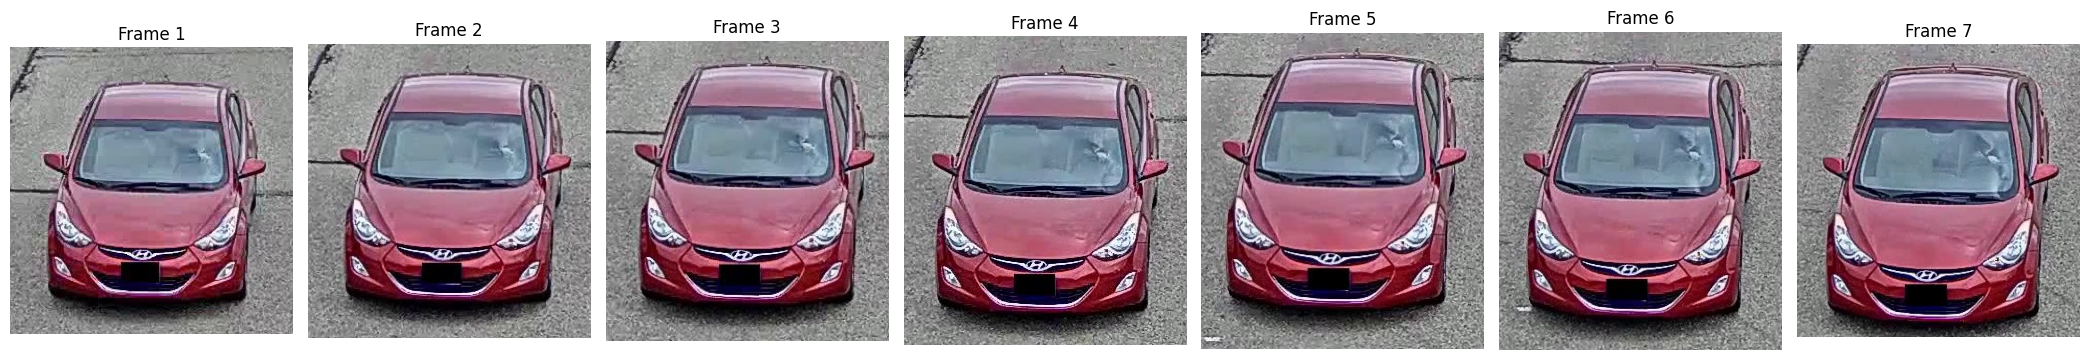

In [44]:
# ============================================================
# CELL 7: Visualize ground-truth vehicle crops
# ============================================================

ground_truth_images = []

for image_info in record["images"]:

    image_path = (
        PROCESSED_ROOT /
        image_info["crop_path"]
    )

    if image_path.exists():

        image = Image.open(
            image_path
        ).convert("RGB")

        ground_truth_images.append(
            (
                image_info["frame_number"],
                image
            )
        )

print(
    "Images successfully loaded:",
    len(ground_truth_images)
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

n = len(ground_truth_images)

fig, axes = plt.subplots(
    1,
    n,
    figsize=(3 * n, 4)
)

if n == 1:
    axes = [axes]

for ax, (
    frame_number,
    image
) in zip(
    axes,
    ground_truth_images
):

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f"Frame {frame_number}"
    )

plt.tight_layout()
plt.show()

In [45]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 8: Query vs Individual Vehicle Frames
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

# ------------------------------------------------------------
# Query
# ------------------------------------------------------------

query = test_query

print("Query:")
print(query)

# ------------------------------------------------------------
# Encode text
# ------------------------------------------------------------

text_embedding = encode_text(
    query
)

text_embedding = F.normalize(
    text_embedding,
    p=2,
    dim=1
)

# ------------------------------------------------------------
# Load ground-truth vehicle images
# ------------------------------------------------------------

ground_truth_images = []

ground_truth_paths = []

for image_info in record["images"]:

    image_path = (
        PROCESSED_ROOT /
        image_info["crop_path"]
    )

    if image_path.exists():

        image = Image.open(
            image_path
        ).convert("RGB")

        ground_truth_images.append(
            image
        )

        ground_truth_paths.append(
            str(image_path)
        )

print(
    "\nNumber of frames:",
    len(ground_truth_images)
)

# ------------------------------------------------------------
# Encode every frame
# ------------------------------------------------------------

frame_embeddings = encode_images(
    ground_truth_images
)

frame_embeddings = F.normalize(
    frame_embeddings,
    p=2,
    dim=1
)

print(
    "Frame embedding shape:",
    frame_embeddings.shape
)

# ------------------------------------------------------------
# Text ↔ every frame similarity
# ------------------------------------------------------------

frame_similarities = (
    text_embedding
    @ frame_embeddings.T
).squeeze(0)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print(
    "\nQuery → individual frame similarities:"
)

for i, similarity in enumerate(
    frame_similarities.tolist(),
    start=1
):

    print(
        f"Frame {i}: "
        f"{similarity:.4f}"
    )

print(
    "\nMean frame similarity:",
    frame_similarities.mean().item()
)

print(
    "Maximum frame similarity:",
    frame_similarities.max().item()
)

print(
    "Minimum frame similarity:",
    frame_similarities.min().item()
)

Query:
A red sedan drives forward.

Number of frames: 7
Frame embedding shape: torch.Size([7, 768])

Query → individual frame similarities:
Frame 1: 0.1481
Frame 2: 0.1463
Frame 3: 0.1456
Frame 4: 0.1480
Frame 5: 0.1488
Frame 6: 0.1500
Frame 7: 0.1462

Mean frame similarity: 0.1475684642791748
Maximum frame similarity: 0.14998416602611542
Minimum frame similarity: 0.1455821990966797


In [46]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 9: Image → Vehicle Retrieval
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# Ground-truth vehicle
# ------------------------------------------------------------

image_query_vehicle_id = test_ground_truth

image_query_record = evaluation_metadata[
    image_query_vehicle_id
]

# ------------------------------------------------------------
# Select first representative crop
# ------------------------------------------------------------

image_info = image_query_record["images"][0]

image_query_path = (
    PROCESSED_ROOT /
    image_info["crop_path"]
)

print("Image query vehicle:")
print(image_query_vehicle_id)

print("\nImage:")
print(image_query_path)

print(
    "\nFile exists:",
    image_query_path.exists()
)

# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------

image_query = Image.open(
    image_query_path
).convert("RGB")

print(
    "\nImage size:",
    image_query.size
)

# ------------------------------------------------------------
# Encode image using SigLIP 2
# ------------------------------------------------------------

image_query_embedding = encode_images(
    [image_query]
)

image_query_embedding = F.normalize(
    image_query_embedding,
    p=2,
    dim=1
)

print(
    "\nEmbedding shape:",
    image_query_embedding.shape
)

print(
    "Embedding norm:",
    image_query_embedding.norm().item()
)

# ------------------------------------------------------------
# Convert to FAISS format
# ------------------------------------------------------------

image_query_vector = (
    image_query_embedding
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)

# ------------------------------------------------------------
# Search gallery
# ------------------------------------------------------------

image_scores, image_indices = index.search(
    image_query_vector,
    10
)

image_retrieved_ids = [
    vehicle_ids[idx]
    for idx in image_indices[0]
]

# ------------------------------------------------------------
# Find ground-truth rank
# ------------------------------------------------------------

image_ground_truth_rank = None

for rank, vehicle_id in enumerate(
    image_retrieved_ids,
    start=1
):

    if vehicle_id == image_query_vehicle_id:

        image_ground_truth_rank = rank

        break

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nTop 10 image-retrieval results:")

for rank, (
    vehicle_id,
    score
) in enumerate(
    zip(
        image_retrieved_ids,
        image_scores[0]
    ),
    start=1
):

    marker = ""

    if vehicle_id == image_query_vehicle_id:
        marker = "  <-- CORRECT"

    print(
        f"{rank:2d}. "
        f"{vehicle_id} "
        f"similarity={score:.4f}"
        f"{marker}"
    )

print(
    "\nGround-truth rank:",
    image_ground_truth_rank
    if image_ground_truth_rank is not None
    else "NOT IN TOP 10"
)

Image query vehicle:
b06c903c-a25d-45fe-b0d5-294f72e34023

Image:
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg

File exists: True

Image size: (273, 277)

Embedding shape: torch.Size([1, 768])
Embedding norm: 1.0

Top 10 image-retrieval results:
 1. b06c903c-a25d-45fe-b0d5-294f72e34023 similarity=0.9858  <-- CORRECT
 2. 3a02a86d-154b-4ee2-bd5e-a0811113a9d8 similarity=0.9248
 3. 78188194-cb69-450b-853c-1f908fbe793d similarity=0.8854
 4. 49f04a86-ff71-4ad9-bd2d-bc836e3bb446 similarity=0.8839
 5. aa624084-d66a-42a2-bab4-f8a32846d62c similarity=0.8762
 6. daaac25a-2e2a-4aff-b617-014a6337e303 similarity=0.8687
 7. 959160ff-95bc-4782-9aa9-ecc3f0d1a0cf similarity=0.8678
 8. 1dc7c242-b8e8-45ae-bcfc-f3827792cf55 similarity=0.8669
 9. 9ed49959-6448-4807-9c81-85d73f61b70a similarity=0.8661
10. eb184f7c-35c7-4f3e-af52-1db57fb087d4 similarity=0.8660

Ground-truth rank: 1


In [47]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 10: Cross-frame Image → Vehicle Retrieval
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# Ground-truth vehicle
# ------------------------------------------------------------

cross_frame_vehicle_id = test_ground_truth

cross_frame_record = evaluation_metadata[
    cross_frame_vehicle_id
]

# ------------------------------------------------------------
# Load all sampled frames
# ------------------------------------------------------------

cross_frame_images = []
cross_frame_numbers = []

for image_info in cross_frame_record["images"]:

    image_path = (
        PROCESSED_ROOT /
        image_info["crop_path"]
    )

    if not image_path.exists():
        continue

    image = Image.open(
        image_path
    ).convert("RGB")

    cross_frame_images.append(image)

    cross_frame_numbers.append(
        image_info["frame_number"]
    )

print(
    "Vehicle:",
    cross_frame_vehicle_id
)

print(
    "Frames loaded:",
    len(cross_frame_images)
)

# ------------------------------------------------------------
# Encode all frames
# ------------------------------------------------------------

cross_frame_embeddings = encode_images(
    cross_frame_images
)

cross_frame_embeddings = F.normalize(
    cross_frame_embeddings,
    p=2,
    dim=1
)

print(
    "Embedding shape:",
    cross_frame_embeddings.shape
)

# ------------------------------------------------------------
# Search each frame independently
# ------------------------------------------------------------

frame_results = []

for i in range(
    len(cross_frame_images)
):

    query_vector = (
        cross_frame_embeddings[i]
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
        .reshape(1, -1)
    )

    scores, indices = index.search(
        query_vector,
        10
    )

    retrieved_ids = [
        vehicle_ids[idx]
        for idx in indices[0]
    ]

    rank = None

    for position, vehicle_id in enumerate(
        retrieved_ids,
        start=1
    ):

        if vehicle_id == cross_frame_vehicle_id:

            rank = position
            break

    frame_results.append({
        "frame_number":
            cross_frame_numbers[i],

        "rank":
            rank,

        "top_score":
            float(scores[0][0])
    })

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print(
    "\nFrame-by-frame retrieval:"
)

for result in frame_results:

    rank_text = (
        str(result["rank"])
        if result["rank"] is not None
        else "NOT TOP-10"
    )

    print(
        f"Frame "
        f"{result['frame_number']:2d}"
        f" → rank={rank_text:>10}"
        f" | top_similarity="
        f"{result['top_score']:.4f}"
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

successful = [
    r
    for r in frame_results
    if r["rank"] is not None
]

print(
    "\nSuccessful Top-10:",
    len(successful),
    "/",
    len(frame_results)
)

if successful:

    print(
        "Recall@1:",
        sum(
            r["rank"] == 1
            for r in successful
        ),
        "/",
        len(frame_results)
    )

    print(
        "Recall@5:",
        sum(
            r["rank"] <= 5
            for r in successful
        ),
        "/",
        len(frame_results)
    )

    print(
        "Recall@10:",
        len(successful),
        "/",
        len(frame_results)
    )

Vehicle: b06c903c-a25d-45fe-b0d5-294f72e34023
Frames loaded: 7
Embedding shape: torch.Size([7, 768])

Frame-by-frame retrieval:
Frame  1 → rank=         1 | top_similarity=0.9858
Frame  2 → rank=         1 | top_similarity=0.9916
Frame  3 → rank=         1 | top_similarity=0.9800
Frame  4 → rank=         1 | top_similarity=0.9925
Frame  5 → rank=         1 | top_similarity=0.9789
Frame  6 → rank=         1 | top_similarity=0.9880
Frame  7 → rank=         1 | top_similarity=0.9858

Successful Top-10: 7 / 7
Recall@1: 7 / 7
Recall@5: 7 / 7
Recall@10: 7 / 7


In [48]:
# ============================================================
# VehicleIQ — Quantitative Evaluation
# CELL 11: Text Query Ablation Study
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

# ------------------------------------------------------------
# Ground truth
# ------------------------------------------------------------

ablation_ground_truth = test_ground_truth

queries = [
    "red sedan",
    "red car",
    "A red sedan drives forward.",
]

print(
    "Ground-truth vehicle:",
    ablation_ground_truth
)

print(
    "\nTesting",
    len(queries),
    "different query formulations..."
)

# ------------------------------------------------------------
# Encode all queries
# ------------------------------------------------------------

query_embeddings = encode_text(
    queries
)

query_embeddings = F.normalize(
    query_embeddings,
    p=2,
    dim=1
)

print(
    "\nEmbedding shape:",
    query_embeddings.shape
)

# ------------------------------------------------------------
# Evaluate each query
# ------------------------------------------------------------

for query, embedding in zip(
    queries,
    query_embeddings
):

    query_vector = (
        embedding
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
        .reshape(1, -1)
    )

    scores, indices = index.search(
        query_vector,
        10
    )

    retrieved_ids = [
        vehicle_ids[idx]
        for idx in indices[0]
    ]

    ground_truth_rank = None

    for rank, vehicle_id in enumerate(
        retrieved_ids,
        start=1
    ):

        if vehicle_id == ablation_ground_truth:

            ground_truth_rank = rank

            break

    print("\n" + "=" * 70)

    print("Query:")
    print(query)

    print(
        "\nGround-truth rank:",
        ground_truth_rank
        if ground_truth_rank is not None
        else "NOT TOP-10"
    )

    print("\nTop 10:")

    for rank, (
        vehicle_id,
        score
    ) in enumerate(
        zip(
            retrieved_ids,
            scores[0]
        ),
        start=1
    ):

        marker = ""

        if vehicle_id == ablation_ground_truth:
            marker = "  <-- CORRECT"

        print(
            f"{rank:2d}. "
            f"{vehicle_id} "
            f"similarity={score:.4f}"
            f"{marker}"
        )

Ground-truth vehicle: b06c903c-a25d-45fe-b0d5-294f72e34023

Testing 3 different query formulations...

Embedding shape: torch.Size([3, 768])

Query:
red sedan

Ground-truth rank: NOT TOP-10

Top 10:
 1. b1f099fd-e45e-4ded-b183-725741959fba similarity=0.1521
 2. b994a201-f6da-4e9c-b5cd-85f667aa816b similarity=0.1498
 3. 610b30a1-5f40-41d0-9c05-fbd1448d3f6e similarity=0.1474
 4. f70f8c5d-bdab-41f5-8f04-a4b7915d1a06 similarity=0.1472
 5. 84345111-4877-4dcf-9331-5ef50aa80fdc similarity=0.1471
 6. 0ee59af3-1502-494b-a3a3-1c4fade7873b similarity=0.1467
 7. 4ad0b436-0bb9-4a2b-a3f7-7b74d3fd8668 similarity=0.1465
 8. cfad5a2f-3aba-450a-8c80-3d76d1dadf62 similarity=0.1462
 9. 3a02a86d-154b-4ee2-bd5e-a0811113a9d8 similarity=0.1460
10. 870e5570-4c79-42ba-bd97-a862d86004f0 similarity=0.1454

Query:
red car

Ground-truth rank: NOT TOP-10

Top 10:
 1. f70f8c5d-bdab-41f5-8f04-a4b7915d1a06 similarity=0.1361
 2. 24be130b-a01f-4bb2-9d77-9192b6a29b93 similarity=0.1356
 3. 0ee59af3-1502-494b-a3a3-1c4fade78

In [49]:
# ============================================================
# VehicleIQ — Diagnostic
# CELL 12: Inspect SigLIP encoding functions
# ============================================================

import inspect

print("=" * 70)
print("encode_images()")
print("=" * 70)

print(
    inspect.getsource(encode_images)
)

print("\n")

print("=" * 70)
print("encode_text()")
print("=" * 70)

print(
    inspect.getsource(encode_text)
)

encode_images()
def encode_images(images):

    if not isinstance(images, list):
        images = [images]

    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if torch.is_tensor(value)
    }

    with torch.inference_mode():

        output = model.get_image_features(
            **inputs
        )

    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings



encode_text()
def encode_text(texts):

    if isinstance(texts, str):
        texts = [texts]

    inputs = processor(
        text=texts,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if torch.is_tensor(

In [50]:
# ============================================================
# VehicleIQ — Diagnostic
# CELL 13: Inspect native SigLIP2 image/text outputs
# ============================================================

# ------------------------------------------------------------
# Prepare one image and one text
# ------------------------------------------------------------

diagnostic_image = image_query
diagnostic_text = test_query

inputs = processor(
    text=[diagnostic_text],
    images=[diagnostic_image],
    padding="max_length",
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
    if torch.is_tensor(value)
}

# ------------------------------------------------------------
# Run the FULL SigLIP2 model
# ------------------------------------------------------------

with torch.inference_mode():

    outputs = model(
        **inputs
    )

# ------------------------------------------------------------
# Inspect output object
# ------------------------------------------------------------

print("=" * 70)
print("MODEL OUTPUT TYPE")
print("=" * 70)

print(
    type(outputs)
)

print("\nAvailable fields:")

if hasattr(outputs, "keys"):
    print(
        list(outputs.keys())
    )

# ------------------------------------------------------------
# Inspect important fields
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE EMBEDS")
print("=" * 70)

if hasattr(outputs, "image_embeds"):

    print(
        "Shape:",
        outputs.image_embeds.shape
    )

    print(
        "Norm:",
        outputs.image_embeds.norm(
            dim=-1
        ).item()
    )

else:

    print(
        "image_embeds not available"
    )

print("\n" + "=" * 70)
print("TEXT EMBEDS")
print("=" * 70)

if hasattr(outputs, "text_embeds"):

    print(
        "Shape:",
        outputs.text_embeds.shape
    )

    print(
        "Norm:",
        outputs.text_embeds.norm(
            dim=-1
        ).item()
    )

else:

    print(
        "text_embeds not available"
    )

print("\n" + "=" * 70)
print("NATIVE IMAGE-TEXT LOGITS")
print("=" * 70)

if hasattr(outputs, "logits_per_image"):

    print(
        "Shape:",
        outputs.logits_per_image.shape
    )

    print(
        "Value:",
        outputs.logits_per_image.item()
    )

else:

    print(
        "logits_per_image not available"
    )

print("\n" + "=" * 70)
print("NATIVE TEXT-IMAGE LOGITS")
print("=" * 70)

if hasattr(outputs, "logits_per_text"):

    print(
        "Shape:",
        outputs.logits_per_text.shape
    )

    print(
        "Value:",
        outputs.logits_per_text.item()
    )

else:

    print(
        "logits_per_text not available"
    )

MODEL OUTPUT TYPE
<class 'transformers.models.siglip.modeling_siglip.SiglipOutput'>

Available fields:
['logits_per_image', 'logits_per_text', 'text_embeds', 'image_embeds', 'text_model_output', 'vision_model_output']

IMAGE EMBEDS
Shape: torch.Size([1, 768])
Norm: 1.0

TEXT EMBEDS
Shape: torch.Size([1, 768])
Norm: 1.0

NATIVE IMAGE-TEXT LOGITS
Shape: torch.Size([1, 1])
Value: -0.08976173400878906

NATIVE TEXT-IMAGE LOGITS
Shape: torch.Size([1, 1])
Value: -0.08976173400878906


In [51]:
# ============================================================
# VehicleIQ — Diagnostic
# CELL 14: Verify actual loaded SigLIP model
# ============================================================

print("=" * 70)
print("MODEL CLASS")
print("=" * 70)

print(
    type(model)
)

print("\n" + "=" * 70)
print("MODEL NAME / PATH")
print("=" * 70)

if hasattr(model, "name_or_path"):
    print(
        model.name_or_path
    )
else:
    print(
        "name_or_path unavailable"
    )

print("\n" + "=" * 70)
print("CONFIG MODEL TYPE")
print("=" * 70)

print(
    getattr(
        model.config,
        "model_type",
        "Not available"
    )
)

print("\n" + "=" * 70)
print("CONFIG ARCHITECTURE")
print("=" * 70)

print(
    getattr(
        model.config,
        "architectures",
        "Not available"
    )
)

print("\n" + "=" * 70)
print("HIDDEN SIZE")
print("=" * 70)

print(
    getattr(
        model.config,
        "hidden_size",
        "Not available"
    )
)

print("\n" + "=" * 70)
print("VISION HIDDEN SIZE")
print("=" * 70)

if hasattr(
    model.config,
    "vision_config"
):

    print(
        getattr(
            model.config.vision_config,
            "hidden_size",
            "Not available"
        )
    )

print("\n" + "=" * 70)
print("TEXT HIDDEN SIZE")
print("=" * 70)

if hasattr(
    model.config,
    "text_config"
):

    print(
        getattr(
            model.config.text_config,
            "hidden_size",
            "Not available"
        )
    )

MODEL CLASS
<class 'transformers.models.siglip.modeling_siglip.SiglipModel'>

MODEL NAME / PATH
google/siglip2-base-patch16-224

CONFIG MODEL TYPE
siglip

CONFIG ARCHITECTURE
None

HIDDEN SIZE
Not available

VISION HIDDEN SIZE
768

TEXT HIDDEN SIZE
768


In [52]:
# ============================================================
# VehicleIQ — Diagnostic
# CELL 15: Check Transformers version
# ============================================================

import transformers

print(
    "Transformers version:",
    transformers.__version__
)

print(
    "PyTorch version:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Transformers version: 5.13.1
PyTorch version: 2.11.0+cpu
CUDA available: False
